# Decoding of the printed full-density arrays

Three $235 \times 363$ arrays (Dual barcodes, Greedy + 2-OPT, Zipcodes) were printed on one slide and sequenced on a MiSeq Micro run. Reads were decoded with QUIK (4-mer strategy, barcode at Read 1 positions 11-46) against the **combined** whitelist of real barcodes plus decoys, at rejection thresholds $r \in \{5, 6, 7\}$.

Notation: $N$ = reads, $A$ = reads assigned to any whitelist entry, $D$ = reads assigned to decoys, $R = A - D$ = reads assigned to real barcodes, $\phi_{\text{global}} = n_D/(n_R+n_D)$.

* Assignment rate: $R/N$.
* Decoy-based precision: $\hat P = 1 - (D/A)/\phi$, with $\phi_{\text{global}}$ and with the effective decoy share $\phi_{\text{eff}}$ measured on 1M simulated reads at the same threshold (`../precision_calibration`). Where no simulation exists for a threshold, $\phi_{\text{eff}}$ is taken as $\phi_{\text{global}}$ times the mean ratio $\phi_{\text{eff}}/\phi_{\text{global}}$ of that layout at the other thresholds (column `phi_eff_source`).
* Recall: estimated fraction of all reads that are correctly assigned, $A\hat P/N$.
* 95% intervals use the exact (Garwood) Poisson interval for $D$, which remains informative when $D = 0$; they do not include the uncertainty of $\phi_{\text{eff}}$.

Spatial analyses use $r = 7$.

In [ ]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
import pandas as pd
from scipy.stats import chi2, spearmanr

plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42})

DATA = Path("../../data")
LAYOUT_DIR = DATA / "1in1"
QUIK_DIR = DATA / "quik_out_manuscript"
DECOY_DIR = DATA / "decoys" / "output"
CALIBRATION = Path("../precision_calibration/precision_calibration_1M.csv")
OUT_DIR = Path(".")
ROWS, COLS, SEG = 235, 363, 18
THRESHOLDS = [5, 6, 7]
SPATIAL_R = 7

ARRAYS = {
    "Dual barcodes": {"dir": "dual_combined_decoy_thr{r}", "sample": "26_018_S1"},
    "Greedy + 2-OPT": {"dir": "greedy_combined_decoy_thr{r}", "sample": "26_018_S3"},
    "Zipcodes": {"dir": "zipcodesV2_combined_decoy_thr{r}", "sample": "26_018_S4"},
}


def run_prefix(name, r):
    cfg = ARRAYS[name]
    return QUIK_DIR / cfg["dir"].format(r=r) / f"{cfg['sample']}_quik"

## Layouts

All three layout files list barcodes in column-major order. The Greedy coordinate file stores (column, row), so its axes are swapped here to match the other two.

In [2]:
def load_layout(name):
    if name == "Dual barcodes":
        df = pd.read_csv(LAYOUT_DIR / "layout_235x363_dual_4x4.csv").rename(columns={"combined": "barcode"})
    elif name == "Zipcodes":
        df = pd.read_csv(LAYOUT_DIR / "layout_235x363_zipcodes_nosep.csv")
    else:
        df = pd.read_csv(LAYOUT_DIR / "layout_235x363_randombarcodes_opt_coords.csv", header=None,
                         names=["barcode", "col", "row"])
    df["barcode"] = df.barcode.str.upper()
    assert df.barcode.is_unique and len(df) == ROWS * COLS
    assert df.row.max() == ROWS - 1 and df.col.max() == COLS - 1
    return df[["row", "col", "barcode"]]


layouts = {name: load_layout(name) for name in ARRAYS}
{name: df.shape for name, df in layouts.items()}

{'Dual barcodes': (85305, 3),
 'Greedy + 2-OPT': (85305, 3),
 'Zipcodes': (85305, 3)}

## Assignments

In [3]:
HEADER = re.compile(r"_calledidx_(\d+)_([ACGTN]+)\s")


def read_called(path):
    seqs = []
    with open(path) as handle:
        for i, line in enumerate(handle):
            if i % 4 == 0:
                match = HEADER.search(line)
                if match is None:
                    raise ValueError(f"Unexpected header in {path}: {line!r}")
                seqs.append(match[2])
    return pd.Series(seqs, name="called_seq")


def read_calling_stats(path):
    text = Path(path).read_text()
    return {
        "whitelist_file": re.search(r"Reading barcodes from: (\S+)", text)[1],
        "whitelist_size": int(re.search(r"Loaded (\d+) barcodes", text)[1]),
        "total_reads": int(re.search(r"Total reads: (\d+)", text)[1]),
        "assigned_reads": int(re.search(r"Assigned reads: (\d+)", text)[1]),
        "threshold": int(re.search(r"Rejection threshold: (\d+)", text)[1]),
        "barcode_start": int(re.search(r"Barcode start position: (\d+)", text)[1]),
        "strategy": re.search(r"Strategy: (\S+)", text)[1],
    }


called, stats = {}, {}
for name in ARRAYS:
    for r in THRESHOLDS:
        st = read_calling_stats(f"{run_prefix(name, r)}_barcode_calling_stats.txt")
        assert st["threshold"] == r
        called[(name, r)] = read_called(f"{run_prefix(name, r)}_R1_filtered.fastq")
        assert len(called[(name, r)]) == st["assigned_reads"]
        stats[(name, r)] = st
pd.DataFrame(stats).T.rename_axis(["layout", "threshold"])

whitelist_file  \
layout         threshold                                          
Dual barcodes  5            dual_whitelist_real_plus_decoys.txt   
               6            dual_whitelist_real_plus_decoys.txt   
               7            dual_whitelist_real_plus_decoys.txt   
Greedy + 2-OPT 5          greedy_whitelist_real_plus_decoys.txt   
               6          greedy_whitelist_real_plus_decoys.txt   
               7          greedy_whitelist_real_plus_decoys.txt   
Zipcodes       5             zip_whitelist_real_plus_decoys.txt   
               6             zip_whitelist_real_plus_decoys.txt   
               7             zip_whitelist_real_plus_decoys.txt   

                         whitelist_size total_reads assigned_reads threshold  \
layout         threshold                                                       
Dual barcodes  5                 127957      372835         130165         5   
               6                 127957      372835         162030         6   
               7                 127957      372835         185607         7   
Greedy + 2-OPT 5                 127957      306222          38275         5   
               6                 127957      306222          53626         6   
               7                 127957      306222          66611         7   
Zipcodes       5                 128107      395770         116840         5   
               6                 128107      395770         156932         6   
               7                 128107      395770         190221         7   

                         barcode_start      strategy  
layout         threshold                              
Dual barcodes  5                    10  4_mer_gpu_v4  
               6                    10  4_mer_gpu_v4  
               7                    10  4_mer_gpu_v4  
Greedy + 2-OPT 5                    10  4_mer_gpu_v4  
               6                    10  4_mer_gpu_v4  
               7                    10  4_mer_gpu_v4  
Zipcodes       5                    10  4_mer_gpu_v4  
               6                    10  4_mer_gpu_v4  
               7                    10  4_mer_gpu_v4

## Assignment rate, precision and recall

In [4]:
calibration = pd.read_csv(CALIBRATION, index_col=["layout", "threshold"])


def phi_eff_for(name, r, phi_global):
    if (name, r) in calibration.index:
        return calibration.loc[(name, r), "phi_eff"], "simulation"
    ratio = calibration.loc[name, "phi_eff_over_phi"].mean()
    return phi_global * ratio, "mean ratio of other thresholds"


def precision(D, A, phi):
    p = 1 - (D / A) / phi
    D_lo = chi2.ppf(0.025, 2 * D) / 2 if D > 0 else 0.0
    D_hi = chi2.ppf(0.975, 2 * (D + 1)) / 2
    return p, 1 - (D_hi / A) / phi, 1 - (D_lo / A) / phi


def evaluate(c, real_set, decoy_set, n_real, n_decoy, N, name, r):
    """decoy_set=None: every called sequence outside real_set is a decoy."""
    D = int((~c.isin(real_set)).sum()) if decoy_set is None else int(c.isin(decoy_set).sum())
    R = int(c.isin(real_set).sum())
    A = R + D
    phi = n_decoy / (n_real + n_decoy)
    phi_full = stats[(name, r)]["whitelist_size"]
    phi_full = (phi_full - len(layouts[name])) / phi_full
    phi_eff, source = phi_eff_for(name, r, phi_full)
    phi_eff *= phi / phi_full
    p_g, lo_g, hi_g = precision(D, A, phi)
    p_e, lo_e, hi_e = precision(D, A, phi_eff)
    return {
        "reads": N, "assigned_any": A, "assigned_decoy": D, "assigned_real": R,
        "n_real": n_real, "n_decoy": n_decoy, "phi_global": phi, "phi_eff": phi_eff, "phi_eff_source": source,
        "assignment_rate_real": R / N, "decoy_fraction_of_assigned": D / A,
        "precision_global": p_g, "precision_global_lo": lo_g, "precision_global_hi": hi_g,
        "precision_calibrated": p_e, "precision_calibrated_lo": lo_e, "precision_calibrated_hi": hi_e,
        "recall_calibrated": A * p_e / N,
    }


rows = []
for name in ARRAYS:
    real_set = set(layouts[name].barcode)
    for r in THRESHOLDS:
        st = stats[(name, r)]
        n_decoy = st["whitelist_size"] - len(real_set)
        row = evaluate(called[(name, r)], real_set, None, len(real_set), n_decoy, st["total_reads"], name, r)
        if (name, r) in calibration.index:
            row["sim_decoy_fraction_of_assigned"] = (calibration.loc[(name, r), "assigned_to_decoys"]
                                                     / calibration.loc[(name, r), "assigned_any"])
        rows.append({"layout": name, "threshold": r, **row})
real_results = pd.DataFrame(rows).set_index(["layout", "threshold"])
real_results.to_csv(OUT_DIR / "real_arrays_full.csv")
real_results

reads  assigned_any  assigned_decoy  assigned_real  \
layout         threshold                                                        
Dual barcodes  5          372835        130165            1744         128421   
               6          372835        162030            5112         156918   
               7          372835        185607            8995         176612   
Greedy + 2-OPT 5          306222         38275               0          38275   
               6          306222         53626              15          53611   
               7          306222         66611             285          66326   
Zipcodes       5          395770        116840            1729         115111   
               6          395770        156932            4975         151957   
               7          395770        190221           10621         179600   

                          n_real  n_decoy  phi_global   phi_eff  \
layout         threshold                                          
Dual barcodes  5           85305    42652    0.333331  0.331529   
               6           85305    42652    0.333331  0.345511   
               7           85305    42652    0.333331  0.336369   
Greedy + 2-OPT 5           85305    42652    0.333331  0.200000   
               6           85305    42652    0.333331  0.329412   
               7           85305    42652    0.333331  0.354605   
Zipcodes       5           85305    42802    0.334111  0.190139   
               6           85305    42802    0.334111  0.188552   
               7           85305    42802    0.334111  0.191445   

                         phi_eff_source  assignment_rate_real  \
layout         threshold                                        
Dual barcodes  5             simulation              0.344445   
               6             simulation              0.420878   
               7             simulation              0.473700   
Greedy + 2-OPT 5             simulation              0.124991   
               6             simulation              0.175072   
               7             simulation              0.216594   
Zipcodes       5             simulation              0.290853   
               6             simulation              0.383953   
               7             simulation              0.453799   

                          decoy_fraction_of_assigned  precision_global  \
layout         threshold                                                 
Dual barcodes  5                            0.013398          0.959805   
               6                            0.031550          0.905350   
               7                            0.048463          0.854611   
Greedy + 2-OPT 5                            0.000000          1.000000   
               6                            0.000280          0.999161   
               7                            0.004279          0.987164   
Zipcodes       5                            0.014798          0.955709   
               6                            0.031702          0.905117   
               7                            0.055835          0.832885   

                          precision_global_lo  precision_global_hi  \
layout         threshold                                             
Dual barcodes  5                     0.957873             0.961669   
               6                     0.902719             0.907927   
               7                     0.851575             0.857600   
Greedy + 2-OPT 5                     0.999711             1.000000   
               6                     0.998616             0.999530   
               7                     0.985584             0.988611   
Zipcodes       5                     0.953571             0.957773   
               6                     0.902443             0.907735   
               7                     0.829676             0.836048   

                          precision_calibrated  precision_calibrated_lo  \
layout         thres

In [5]:
def summary_table(df):
    return pd.DataFrame({
        "Reads": df.reads,
        "Assigned to real barcodes": df.assigned_real,
        "Assignment rate (%)": (df.assignment_rate_real * 100).round(2),
        "Reads on decoys": df.assigned_decoy,
        "Precision, global phi (%)": (df.precision_global * 100).round(2),
        "Precision, calibrated phi (%)": (df.precision_calibrated * 100).round(2),
        "95% interval, calibrated (%)": [f"{lo * 100:.2f}-{hi * 100:.2f}" for lo, hi in
                                         zip(df.precision_calibrated_lo, df.precision_calibrated_hi)],
        "Recall, calibrated (%)": (df.recall_calibrated * 100).round(2),
        "phi_eff source": df.phi_eff_source,
    })


table = summary_table(real_results)
table.to_csv(OUT_DIR / "real_arrays_summary.csv")
table

Reads  Assigned to real barcodes  \
layout         threshold                                      
Dual barcodes  5          372835                     128421   
               6          372835                     156918   
               7          372835                     176612   
Greedy + 2-OPT 5          306222                      38275   
               6          306222                      53611   
               7          306222                      66326   
Zipcodes       5          395770                     115111   
               6          395770                     151957   
               7          395770                     179600   

                          Assignment rate (%)  Reads on decoys  \
layout         threshold                                         
Dual barcodes  5                        34.44             1744   
               6                        42.09             5112   
               7                        47.37             8995   
Greedy + 2-OPT 5                        12.50                0   
               6                        17.51               15   
               7                        21.66              285   
Zipcodes       5                        29.09             1729   
               6                        38.40             4975   
               7                        45.38            10621   

                          Precision, global phi (%)  \
layout         threshold                              
Dual barcodes  5                              95.98   
               6                              90.54   
               7                              85.46   
Greedy + 2-OPT 5                             100.00   
               6                              99.92   
               7                              98.72   
Zipcodes       5                              95.57   
               6                              90.51   
               7                              83.29   

                          Precision, calibrated phi (%)  \
layout         threshold                                  
Dual barcodes  5                                  95.96   
               6                                  90.87   
               7                                  85.59   
Greedy + 2-OPT 5                                 100.00   
               6                                  99.92   
               7                                  98.79   
Zipcodes       5                                  92.22   
               6                                  83.19   
               7                                  70.84   

                         95% interval, calibrated (%)  Recall, calibrated (%)  \
layout         threshold                                                        
Dual barcodes  5                          95.76-96.15                   33.50   
               6                          90.61-91.12                   39.49   
               7                          85.29-85.89                   42.61   
Greedy + 2-OPT 5                         99.95-100.00                   12.50   
               6                          99.86-99.95                   17.50   
               7                          98.64-98.93                   21.49   
Zipcodes       5                          91.84-92.58                   27.22   
               6                          82.71-83.65                   32.99   
               7                          70.27-71.39                   34.05   

                         phi_eff source  
layout         threshold                 
Dual barcodes  5             simulation  
               6             simulation  
               7             simulation  
Greedy + 2-OPT 5             simulation  
               6             simulation  
               7             simulation  
Zipcodes       5             simulation  
               6             simulation  
               7             simulatio

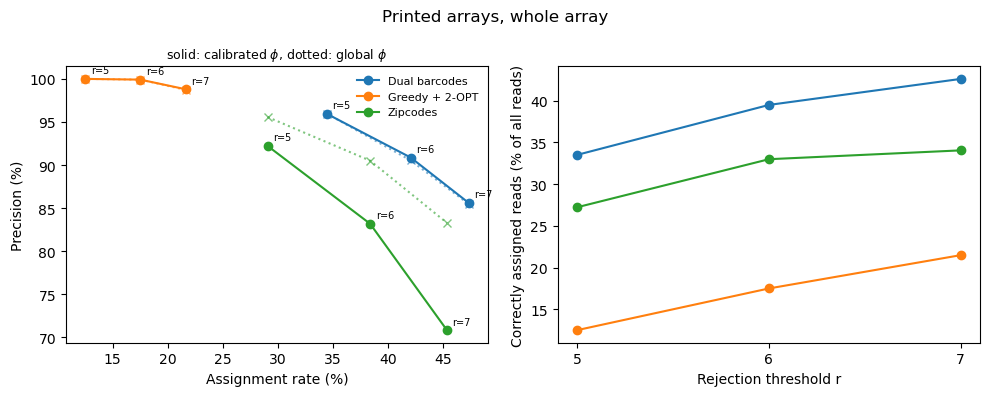

In [6]:
def plot_tradeoff(df, title, path):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for name in ARRAYS:
        d = df.loc[name]
        line, = axes[0].plot(d.assignment_rate_real * 100, d.precision_calibrated * 100, "o-", label=name)
        axes[0].plot(d.assignment_rate_real * 100, d.precision_global * 100, "x:", color=line.get_color(), alpha=0.6)
        for r, x, y in zip(d.index, d.assignment_rate_real * 100, d.precision_calibrated * 100):
            axes[0].annotate(f"r={r}", (x, y), textcoords="offset points", xytext=(4, 4), fontsize=7)
        axes[1].plot(d.index, d.recall_calibrated * 100, "o-", color=line.get_color(), label=name)
    axes[0].set_xlabel("Assignment rate (%)")
    axes[0].set_ylabel("Precision (%)")
    axes[0].set_title("solid: calibrated $\\phi$, dotted: global $\\phi$", fontsize=9)
    axes[0].legend(frameon=False, fontsize=8)
    axes[1].set_xlabel("Rejection threshold r")
    axes[1].set_ylabel("Correctly assigned reads (% of all reads)")
    axes[1].set_xticks(THRESHOLDS)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(path)
    plt.show()


plot_tradeoff(real_results, "Printed arrays, whole array", OUT_DIR / "assignment_vs_precision.pdf")

## Where decoy hits fall (Zipcodes)

A Zipcodes decoy is either a virtual column code with a real row code or a real column code with a virtual row code. The split of decoy hits between the two axes is compared between real and simulated reads.

In [7]:
zip_decoys = pd.read_csv(DECOY_DIR / "zipcodes_balanced_khalf" / "zip_decoysv2.csv").set_index("barcode")


def sim_called(r):
    path = QUIK_DIR / f"simreads_thr{r}_1M" / "quik_zipV2_combined_1M_R1_filtered.fastq"
    with open(path) as handle:
        return pd.Series([line.strip().split("_")[-1] for i, line in enumerate(handle) if i % 4 == 0])


splits = {}
for r in THRESHOLDS:
    splits[(r, "real reads")] = zip_decoys.axis.reindex(called[("Zipcodes", r)]).dropna().value_counts(normalize=True)
    splits[(r, "simulated reads")] = zip_decoys.axis.reindex(sim_called(r)).dropna().value_counts(normalize=True)
axis_split = pd.DataFrame(splits).round(3)
axis_split.index = [f"virtual {a} code" for a in axis_split.index]
axis_split.columns.names = ["threshold", "reads"]
axis_split.to_csv(OUT_DIR / "zipcodes_decoy_axis_split.csv")
axis_split

threshold                    5                          6                  \
reads               real reads simulated reads real reads simulated reads   
virtual row code         0.989           0.919      0.972           0.882   
virtual column code      0.011           0.081      0.028           0.118   

threshold                    7                  
reads               real reads simulated reads  
virtual row code         0.958           0.837  
virtual column code      0.042           0.163

## Reads per feature ($r = 7$)

In [8]:
grids, coverage = {}, []
for name in ARRAYS:
    lay = layouts[name]
    counts = called[(name, SPATIAL_R)].value_counts()
    lay = lay.assign(reads=counts.reindex(lay.barcode).fillna(0).astype(int).values)
    layouts[name] = lay
    grid = np.zeros((ROWS, COLS), dtype=int)
    grid[lay.row, lay.col] = lay.reads
    grids[name] = grid
    res = real_results.loc[(name, SPATIAL_R)]
    coverage.append({
        "layout": name,
        "features_detected (%)": round((lay.reads > 0).mean() * 100, 2),
        "mean reads per real barcode": round(lay.reads.mean(), 3),
        "median reads per detected feature": lay.reads[lay.reads > 0].median(),
        "mean reads per decoy": round(res.assigned_decoy / res.n_decoy, 3),
        "max reads per feature": lay.reads.max(),
    })
pd.DataFrame(coverage).set_index("layout")

,features_detected (%),mean reads per real barcode,median reads per detected feature,mean reads per decoy,max reads per feature
layout,,,,,
Dual barcodes,63.34,2.070,2.0,0.211,34
Greedy + 2-OPT,45.09,0.778,1.0,0.007,93
Zipcodes,66.50,2.105,2.0,0.248,35


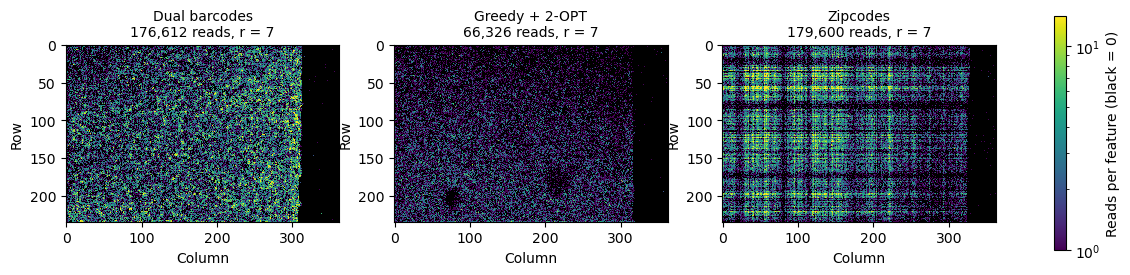

In [9]:
vmax = max(np.percentile(g[g > 0], 99) for g in grids.values())


def plot_heatmaps(crop, reads, suffix, path_stem):
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    for ax, (name, grid) in zip(axes, grids.items()):
        g = grid[:, :crop[name]]
        im = ax.imshow(np.ma.masked_equal(g, 0), cmap="viridis", norm=LogNorm(vmin=1, vmax=vmax),
                       interpolation="nearest", aspect="equal")
        ax.set_facecolor("black")
        ax.set_title(f"{name}\n{suffix}{reads[name]:,} reads, r = {SPATIAL_R}", fontsize=10)
        ax.set_xlabel("Column")
        ax.set_ylabel("Row")
    fig.colorbar(im, ax=axes, shrink=0.8, label="Reads per feature (black = 0)")
    fig.savefig(OUT_DIR / f"{path_stem}.pdf", dpi=300, bbox_inches="tight")
    fig.savefig(OUT_DIR / f"{path_stem}.png", dpi=200, bbox_inches="tight")
    plt.show()


plot_heatmaps({n: COLS for n in ARRAYS},
              {n: int(real_results.loc[(n, SPATIAL_R), "assigned_real"]) for n in ARRAYS},
              "", "reads_per_feature_thr7")

## Zipcodes: read density and G content of the axis codes ($r = 7$)

Every feature in a row shares the row code (last 18 nt) and every feature in a column shares the column code (first 18 nt). If G-rich axis codes are synthesized poorly, the mean read count of a row or column should decrease with the G content of its code.

In [10]:
def axis_g_analysis(zip_lay, path=None):
    tables, correlations = {}, []
    for axis, part in [("col", slice(0, SEG)), ("row", slice(SEG, 2 * SEG))]:
        t = zip_lay.assign(code=zip_lay.barcode.str[part]).groupby(axis).agg(
            code=("code", "first"), mean_reads=("reads", "mean"))
        t["G_fraction"] = t.code.str.count("G") / SEG
        tables[axis] = t
        rho, p = spearmanr(t.G_fraction, t.mean_reads)
        correlations.append({"axis": axis, "n": len(t), "spearman_rho": round(rho, 3), "p_value": p})
    if path is not None:
        fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
        for ax, (axis, t) in zip(axes, tables.items()):
            ax.scatter(t.G_fraction * 100, t.mean_reads, s=10, alpha=0.6)
            ax.set_xlabel(f"G content of {axis} code (%)")
            ax.set_title(f"Zipcodes: mean reads per {axis}")
        axes[0].set_ylabel("Mean reads per feature")
        fig.tight_layout()
        fig.savefig(path)
        plt.show()
    return pd.DataFrame(correlations)


def composition_groups(zip_lay):
    groups = {"Low (1 read)": zip_lay[zip_lay.reads == 1], "High (>4 reads)": zip_lay[zip_lay.reads > 4]}
    out = {}
    for label, g in groups.items():
        comp = pd.DataFrame({b: g.barcode.str.count(b) / 36 * 100 for b in "ACGT"})
        out[(f"{label}, n = {len(g):,}", "mean")] = comp.mean()
        out[(f"{label}, n = {len(g):,}", "std")] = comp.std()
    return pd.DataFrame(out).round(2)


zip_lay = layouts["Zipcodes"]
display(axis_g_analysis(zip_lay))
composition_groups(zip_lay)

,axis,n,spearman_rho,p_value
0,col,363,-0.807,1.460774e-84
1,row,235,-0.881,1.373102e-77


Low (1 read), n = 17,932       High (>4 reads), n = 12,014      
                      mean   std                        mean   std
A                    24.45  6.33                       30.45  6.95
C                    25.97  7.31                       26.56  7.62
G                    24.98  5.44                       15.32  4.70
T                    24.60  7.71                       27.67  7.86

## Printed area only

The gasket that separates the four chambers of the slide was misplaced, leaving a band of columns on the right side of each array without reads. The band is detected per array (at $r = 7$) as the first column from which at least 95% of the remaining columns have a mean read count below 10% of the median of columns 0-299. For Dual barcodes the boundary is moved to the start of the $4 \times 4$ block.

Metrics are then recomputed on the printed area:

* real barcodes: only features left of the band;
* decoys: Dual, decoys of blocks entirely left of the band; Zipcodes, virtual column codes between two printed columns and virtual row codes combined with printed columns; Greedy, all decoys, because they are not tied to positions;
* $\phi$ is recomputed from the retained real barcodes and decoys, and $\phi_{\text{eff}}$ is scaled by the same factor.

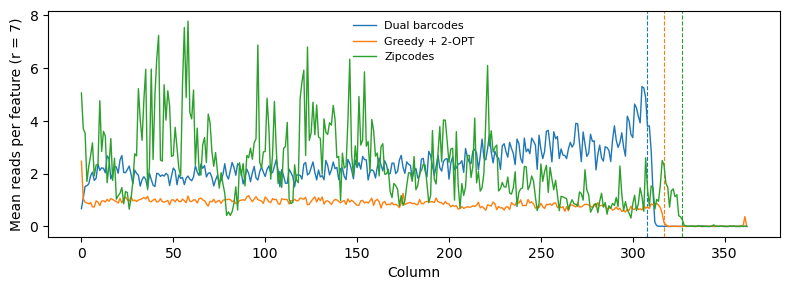

,first excluded column,excluded columns,excluded features (%),reads on excluded features (r = 7)
Dual barcodes,308,55,15.2,2870
Greedy + 2-OPT,317,46,12.7,186
Zipcodes,327,36,9.9,149


In [11]:
def dead_band_start(grid, ref_cols=300, frac_below=0.95, rel_threshold=0.1):
    col_mean = grid.mean(axis=0)
    below = col_mean < rel_threshold * np.median(col_mean[:ref_cols])
    for c in range(grid.shape[1]):
        if below[c:].mean() >= frac_below:
            return c
    return grid.shape[1]


dead_start = {name: dead_band_start(grid) for name, grid in grids.items()}
dead_start["Dual barcodes"] = 4 * (dead_start["Dual barcodes"] // 4)

fig, ax = plt.subplots(figsize=(8, 3))
for name, grid in grids.items():
    line, = ax.plot(grid.mean(axis=0), lw=1, label=name)
    ax.axvline(dead_start[name], ls="--", lw=0.8, color=line.get_color())
ax.set_xlabel("Column")
ax.set_ylabel(f"Mean reads per feature (r = {SPATIAL_R})")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / "column_profiles_dead_band_thr7.pdf")
plt.show()

pd.DataFrame({
    "first excluded column": dead_start,
    "excluded columns": {n: COLS - s for n, s in dead_start.items()},
    "excluded features (%)": {n: round((COLS - s) / COLS * 100, 1) for n, s in dead_start.items()},
    "reads on excluded features (r = 7)": {n: int(grids[n][:, s:].sum()) for n, s in dead_start.items()},
})

In [12]:
dual_decoys = pd.read_csv(DECOY_DIR / "dual" / "dual_decoys.csv")
zip_decoy_table = zip_decoys.reset_index()


def kept_decoys(name, start):
    if name == "Dual barcodes":
        return set(dual_decoys.combined[dual_decoys.block_col * 4 + 3 < start])
    if name == "Zipcodes":
        keep = np.where(zip_decoy_table.axis == "column", zip_decoy_table.gap + 1 < start,
                        zip_decoy_table.col < start)
        return set(zip_decoy_table.barcode[keep])
    return None


rows = []
for name in ARRAYS:
    lay = layouts[name]
    printed = set(lay.barcode[lay.col < dead_start[name]])
    kept = kept_decoys(name, dead_start[name])
    for r in THRESHOLDS:
        st = stats[(name, r)]
        n_decoy = st["whitelist_size"] - len(lay) if kept is None else len(kept)
        c = called[(name, r)]
        if kept is None:
            c = c[c.isin(printed) | ~c.isin(set(lay.barcode))]
        row = evaluate(c, printed, kept, len(printed), n_decoy, st["total_reads"], name, r)
        rows.append({"layout": name, "threshold": r, **row})
printed_results = pd.DataFrame(rows).set_index(["layout", "threshold"])
printed_results.to_csv(OUT_DIR / "real_arrays_printed_area_full.csv")

printed_table = summary_table(printed_results)
printed_table.to_csv(OUT_DIR / "real_arrays_printed_area_summary.csv")

metrics = ["assignment_rate_real", "precision_global", "precision_calibrated", "recall_calibrated"]
comparison = pd.concat({"Whole array": real_results[metrics], "Printed area": printed_results[metrics]}, axis=1)
comparison = (comparison * 100).round(2).swaplevel(axis=1).sort_index(axis=1, level=0)
comparison.to_csv(OUT_DIR / "real_arrays_whole_vs_printed.csv")
comparison

assignment_rate_real              \
                                 Printed area Whole array   
layout         threshold                                    
Dual barcodes  5                        33.92       34.44   
               6                        41.43       42.09   
               7                        46.60       47.37   
Greedy + 2-OPT 5                        12.49       12.50   
               6                        17.50       17.51   
               7                        21.60       21.66   
Zipcodes       5                        29.07       29.09   
               6                        38.37       38.40   
               7                        45.34       45.38   

                         precision_calibrated             precision_global  \
                                 Printed area Whole array     Printed area   
layout         threshold                                                     
Dual barcodes  5                        95.95       95.96            95.97   
               6                        90.85       90.87            90.52   
               7                        85.60       85.59            85.47   
Greedy + 2-OPT 5                       100.00      100.00           100.00   
               6                        99.92       99.92            99.92   
               7                        98.89       98.79            98.82   
Zipcodes       5                        92.22       92.22            95.57   
               6                        83.24       83.19            90.54   
               7                        70.94       70.84            83.35   

                                     recall_calibrated              
                         Whole array      Printed area Whole array  
layout         threshold                                            
Dual barcodes  5               95.98             32.99       33.50  
               6               90.54             38.87       39.49  
               7               85.46             41.92       42.61  
Greedy + 2-OPT 5              100.00             12.49       12.50  
               6               99.92             17.49       17.50  
               7               98.72             21.45       21.49  
Zipcodes       5               95.57             27.22       27.22  
               6               90.51             32.99       32.99  
               7               83.29             34.06       34.05

Features detected, r = 7                 
                        whole array (%) printed area (%)
Dual barcodes                     63.34            73.72
Greedy + 2-OPT                    45.09            51.52
Zipcodes                          66.50            73.66

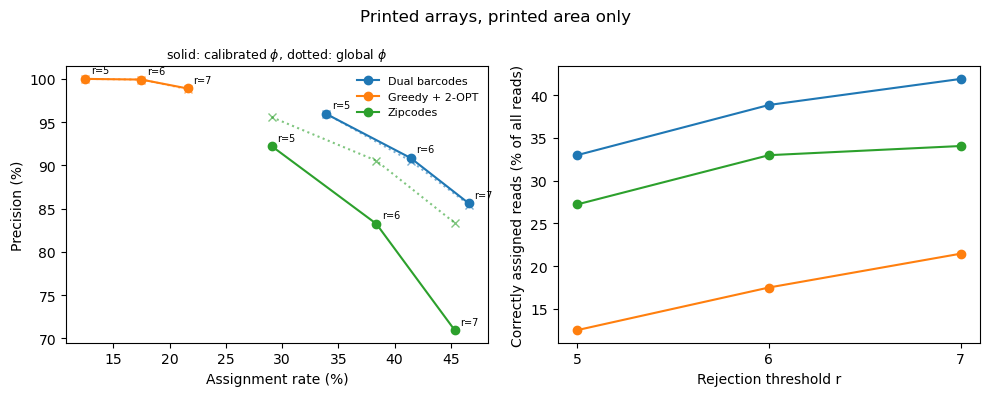

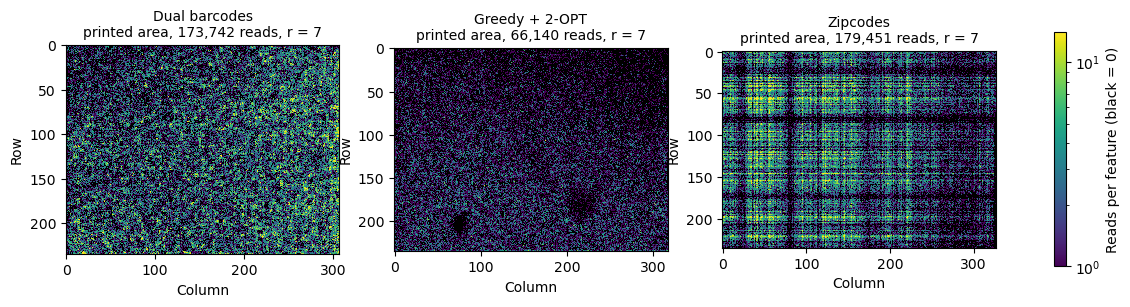

In [13]:
detection = pd.DataFrame({
    "whole array (%)": {n: round((layouts[n].reads > 0).mean() * 100, 2) for n in ARRAYS},
    "printed area (%)": {n: round((layouts[n].reads[layouts[n].col < dead_start[n]] > 0).mean() * 100, 2)
                         for n in ARRAYS},
})
detection.columns = pd.MultiIndex.from_product([[f"Features detected, r = {SPATIAL_R}"], detection.columns])
display(detection)

plot_tradeoff(printed_results, "Printed arrays, printed area only", OUT_DIR / "assignment_vs_precision_printed_area.pdf")
plot_heatmaps(dead_start,
              {n: int(printed_results.loc[(n, SPATIAL_R), "assigned_real"]) for n in ARRAYS},
              "printed area, ", "reads_per_feature_printed_area_thr7")

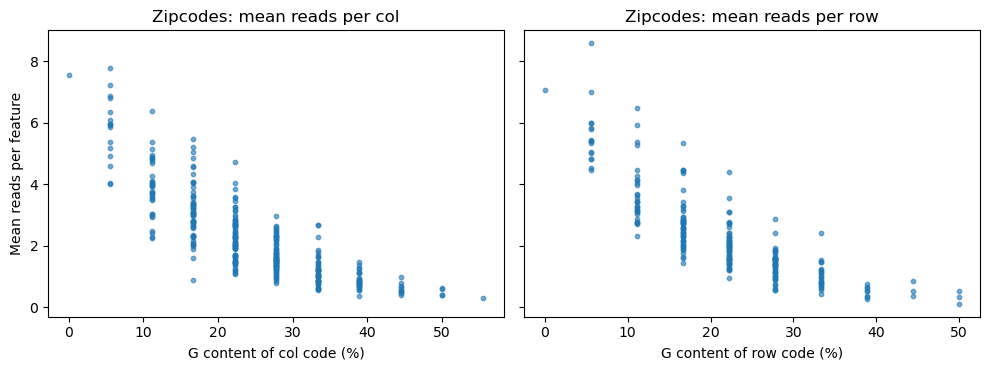

,axis,n,spearman_rho,p_value
0,col,327,-0.866,4.963220e-100
1,row,235,-0.881,1.679675e-77


Low (1 read), n = 17,829       High (>4 reads), n = 12,012      
                      mean   std                        mean   std
A                    24.46  6.33                       30.45  6.95
C                    25.98  7.32                       26.57  7.62
G                    25.00  5.43                       15.32  4.70
T                    24.57  7.70                       27.67  7.86

In [14]:
zip_printed = zip_lay[zip_lay.col < dead_start["Zipcodes"]]
display(axis_g_analysis(zip_printed, OUT_DIR / "zipcodes_axis_G_vs_reads_printed_area_thr7.pdf"))
composition_groups(zip_printed)

In [15]:
for name in ARRAYS:
    key = name.split()[0].lower()
    layouts[name].to_csv(OUT_DIR / f"reads_per_feature_{key}_thr7.csv", index=False)